In [4]:
"""
Market Risk Pipeline
====================
Computes VaR / ES under three models (Historical, GARCH, EVT)
across two market regimes (Volatility, Drawdown) and validates
them with Kupiec's POF test and an ES exceedance ratio test.

Usage
-----
    python risk_pipeline.py                        # defaults
    python risk_pipeline.py --ticker QQQ --start 2010-01-01
    python risk_pipeline.py --alpha 0.01 --window 504
"""

from __future__ import annotations

import argparse
import logging
import warnings
from dataclasses import dataclass, field
from typing import Dict, Tuple

import numpy as np
import pandas as pd
from arch import arch_model
from scipy import stats

warnings.filterwarnings("ignore")

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s  %(levelname)-8s  %(message)s",
    datefmt="%H:%M:%S",
)
log = logging.getLogger(__name__)


# ---------------------------------------------------------------------------
# Config
# ---------------------------------------------------------------------------

@dataclass
class Config:
    ticker: str = "^GSPC"
    start:  str = "2015-01-01"
    alpha:  float = 0.05          # VaR / ES confidence tail probability
    window: int   = 252           # rolling estimation window (trading days)

    # Regime thresholds
    vol_window:      int   = 21
    vol_quantile:    float = 0.95
    dd_threshold:    float = 0.20  # 20 % peak-to-trough

    # GARCH fitting cadence
    garch_refit_step: int = 50
    # EVT subsampling cadence
    evt_step:         int = 5
    # Minimum tail exceedances for GPD fit
    evt_min_exc:      int = 10


# ---------------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------------

def fetch_data(cfg: Config) -> pd.DataFrame:
    """Download OHLCV, compute log-returns, drop NaNs."""
    try:
        import yfinance as yf
    except ImportError as exc:
        raise SystemExit("yfinance is required:  pip install yfinance") from exc

    log.info("Downloading %s from %s …", cfg.ticker, cfg.start)
    raw = yf.download(cfg.ticker, start=cfg.start, auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"No data returned for ticker '{cfg.ticker}'.")

    df = raw[["Close"]].copy()
    df.columns = ["price"]
    df["return"] = np.log(df["price"] / df["price"].shift(1))
    return df.dropna()


# ---------------------------------------------------------------------------
# Regime detection
# ---------------------------------------------------------------------------

def volatility_regime(returns: pd.Series, window: int, quantile: float) -> pd.Series:
    """1 when realised volatility ≥ its historical *quantile* percentile."""
    ann_vol = returns.rolling(window).std() * np.sqrt(252)
    threshold = ann_vol.quantile(quantile)
    return (ann_vol >= threshold).astype(int).rename("vol_regime")


def drawdown_regime(price: pd.Series, threshold: float) -> pd.Series:
    """1 when price is more than *threshold* below its running maximum."""
    drawdown = (price - price.cummax()) / price.cummax()
    return (drawdown <= -threshold).astype(int).rename("dd_regime")


# ---------------------------------------------------------------------------
# Risk models
# ---------------------------------------------------------------------------

class RiskModels:
    """VaR and ES estimates from three methods: Historical, GARCH, EVT."""

    def __init__(self, cfg: Config) -> None:
        self.cfg = cfg

    # ------------------------------------------------------------------ #
    # Historical simulation
    # ------------------------------------------------------------------ #
    def historical(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        """Rolling empirical quantile & conditional tail mean."""
        w, a = self.cfg.window, self.cfg.alpha

        var = -r.rolling(w).quantile(a)
        es  = r.rolling(w).apply(
            lambda x: -x[x <= np.quantile(x, a)].mean(),
            raw=True,
        )
        return var, es

    # ------------------------------------------------------------------ #
    # GARCH(1,1) — Normal innovations
    # ------------------------------------------------------------------ #
    def garch(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        """
        One-step-ahead VaR / ES from a GARCH(1,1) model.
        Model is refit every *garch_refit_step* observations to cut runtime
        while keeping estimates reasonably fresh.
        """
        cfg  = self.cfg
        q_z  = stats.norm.ppf(cfg.alpha)          # z-score of VaR quantile
        pdf_z = stats.norm.pdf(q_z)

        var_list, es_list = [], []
        last_res = None
        idx      = r.index[cfg.window:]

        log.info("Fitting GARCH(1,1) …")
        for i in range(cfg.window, len(r)):
            refit = (last_res is None) or (i % cfg.garch_refit_step == 0)
            if refit:
                try:
                    res = arch_model(r.iloc[:i] * 100,
                                     vol="Garch", p=1, q=1,
                                     dist="normal").fit(disp="off")
                    last_res = res
                except Exception:
                    pass   # keep last good model

            if last_res is None:
                var_list.append(np.nan)
                es_list.append(np.nan)
                continue

            sigma = np.sqrt(last_res.forecast(horizon=1).variance.values[-1, 0]) / 100
            var_list.append(-sigma * q_z)                       # positive number
            es_list.append( sigma * pdf_z / cfg.alpha)

        return pd.Series(var_list, index=idx), pd.Series(es_list, index=idx)

    # ------------------------------------------------------------------ #
    # Extreme Value Theory — Peaks-over-Threshold (GPD)
    # ------------------------------------------------------------------ #
    def evt(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        """
        VaR and ES from a Generalised Pareto fit to tail exceedances.
        Subsampled every *evt_step* days; intermediate days reuse last estimate.
        """
        cfg = self.cfg
        var_list, es_list = [], []
        last_var = last_es = np.nan

        log.info("Fitting EVT (POT / GPD) …")
        for i in range(cfg.window, len(r)):
            if i % cfg.evt_step != 0:
                var_list.append(last_var)
                es_list.append(last_es)
                continue

            losses = -r.iloc[i - cfg.window : i].values
            u      = np.percentile(losses, 90)
            excess = losses[losses > u] - u

            if len(excess) < cfg.evt_min_exc:
                # Fall back to empirical quantile when tail is too thin
                v = float(np.percentile(losses, (1 - cfg.alpha) * 100))
                e = float(losses[losses > v].mean()) if (losses > v).any() else v
            else:
                xi, _, beta = stats.genpareto.fit(excess, floc=0)
                n_u = len(excess)
                n   = len(losses)

                # VaR via GPD inversion
                v = u + (beta / xi) * ((n / n_u * cfg.alpha) ** (-xi) - 1) \
                    if xi != 0 else u - beta * np.log(n / n_u * cfg.alpha)

                # ES (closed form, valid for xi < 1)
                if xi < 1:
                    e = (v + beta - xi * u) / (1 - xi)
                else:
                    e = v   # undefined → conservative fallback

            last_var, last_es = float(v), float(e)
            var_list.append(last_var)
            es_list.append(last_es)

        idx = r.index[cfg.window:]
        return pd.Series(var_list, index=idx), pd.Series(es_list, index=idx)


# ---------------------------------------------------------------------------
# Backtests
# ---------------------------------------------------------------------------

def kupiec_pof(returns: pd.Series, var: pd.Series, alpha: float) -> float:
    """
    Kupiec (1995) Proportion-of-Failures likelihood-ratio test.
    H0: true exceedance rate equals *alpha*.
    Returns p-value (high = model not rejected).
    """
    hits = (returns < -var).astype(int)
    x, N = int(hits.sum()), len(hits)

    if x == 0 or x == N:
        return np.nan                    # degenerate — can't compute LR

    p = x / N
    lr = -2 * (
        x * np.log(alpha / p) + (N - x) * np.log((1 - alpha) / (1 - p))
    )
    return float(1 - stats.chi2.cdf(lr, df=1))


def es_exceedance_ratio(
    returns: pd.Series, var: pd.Series, es: pd.Series
) -> float:
    """
    McNeil & Frey (2000) inspired ES test.
    Computes the mean ratio of realised tail losses to their ES forecast.
    A ratio near 1 → good calibration; > 1 → ES underestimated (too risky).
    Returns NaN if fewer than 10 tail observations.
    """
    mask = returns < -var
    if mask.sum() < 10:
        return np.nan

    tail_losses  = -returns[mask]
    es_forecasts = es[mask]

    # Guard against zero/negative ES forecasts
    valid = es_forecasts > 0
    if valid.sum() < 5:
        return np.nan

    return float((tail_losses[valid] / es_forecasts[valid]).mean())


# ---------------------------------------------------------------------------
# Pipeline
# ---------------------------------------------------------------------------

def build_risk_table(r: pd.Series, cfg: Config) -> pd.DataFrame:
    rm = RiskModels(cfg)

    log.info("Computing Historical VaR/ES …")
    v_hist, e_hist = rm.historical(r)
    log.info("Computing GARCH VaR/ES …")
    v_garch, e_garch = rm.garch(r)
    log.info("Computing EVT VaR/ES …")
    v_evt, e_evt = rm.evt(r)

    risk = pd.DataFrame({
        "var_hist":  v_hist,
        "es_hist":   e_hist,
        "var_garch": v_garch,
        "es_garch":  e_garch,
        "var_evt":   v_evt,
        "es_evt":    e_evt,
    }).dropna()

    log.info("Risk table built: %d rows, %s → %s",
             len(risk), risk.index[0].date(), risk.index[-1].date())
    return risk


def run_backtests(
    r: pd.Series,
    risk: pd.DataFrame,
    regimes: Dict[str, pd.Series],
    cfg: Config,
) -> pd.DataFrame:
    """
    Returns a tidy DataFrame with one row per (regime_name, regime_label, model).
    Columns: observations, exceedances, kupiec_p, es_ratio.
    """
    records = []
    models  = ["hist", "garch", "evt"]
    labels  = {0: "Normal", 1: "Stress"}

    for regime_name, regime_series in regimes.items():
        aligned = regime_series.reindex(risk.index)

        for regime_val, regime_label in labels.items():
            mask   = aligned == regime_val
            sub_r  = r.reindex(risk.index)[mask]

            for model in models:
                var = risk[f"var_{model}"][mask]
                es  = risk[f"es_{model}"][mask]

                kp = kupiec_pof(sub_r, var, cfg.alpha)
                zr = es_exceedance_ratio(sub_r, var, es)

                records.append({
                    "regime":      regime_name,
                    "state":       regime_label,
                    "model":       model.upper(),
                    "n_obs":       int(mask.sum()),
                    "n_exceed":    int((sub_r < -var).sum()),
                    "kupiec_p":    round(kp,  4) if not np.isnan(kp)  else np.nan,
                    "es_ratio":    round(zr,  3) if not np.isnan(zr)  else np.nan,
                })

    return pd.DataFrame(records)


def print_results(results: pd.DataFrame, cfg: Config) -> None:
    """Pretty-print the results table to stdout."""
    sep  = "─" * 72
    hdr  = f"{'Regime':<12}{'State':<10}{'Model':<8}"  \
           f"{'N':>6}{'Exceeds':>9}{'Kupiec p':>11}{'ES ratio':>10}"

    print(f"\n{'Market Risk Backtest Results':^72}")
    print(f"Ticker: {cfg.ticker}  |  alpha={cfg.alpha}  |  window={cfg.window}d")
    print(sep)
    print(hdr)
    print(sep)

    prev_regime = None
    for _, row in results.iterrows():
        if row["regime"] != prev_regime:
            if prev_regime is not None:
                print()
            prev_regime = row["regime"]

        kp  = f"{row['kupiec_p']:.4f}" if not np.isnan(row["kupiec_p"])  else "  n/a"
        zr  = f"{row['es_ratio']:.3f}" if not np.isnan(row["es_ratio"])  else "  n/a"
        ok  = "✓" if (not np.isnan(row["kupiec_p"]) and row["kupiec_p"] > 0.05) else "✗"

        print(
            f"{row['regime']:<12}{row['state']:<10}{row['model']:<8}"
            f"{row['n_obs']:>6}{row['n_exceed']:>9}{kp:>11}{zr:>10}  {ok}"
        )

    print(sep)
    print("✓ Kupiec p > 0.05 → VaR not rejected at 5 % level")
    print("ES ratio ≈ 1.0    → ES well-calibrated  (> 1 = underestimated)")
    print()


def run(cfg: Config | None = None) -> pd.DataFrame:
    if cfg is None:
        cfg = Config()

    df = fetch_data(cfg)
    r  = df["return"]

    regimes: Dict[str, pd.Series] = {
        "Volatility": volatility_regime(r, cfg.vol_window, cfg.vol_quantile),
        "Drawdown":   drawdown_regime(df["price"], cfg.dd_threshold),
    }

    risk    = build_risk_table(r, cfg)
    results = run_backtests(r, risk, regimes, cfg)
    print_results(results, cfg)
    return results


# ---------------------------------------------------------------------------
# CLI
# ---------------------------------------------------------------------------

def _is_jupyter() -> bool:
    """Return True when running inside a Jupyter / IPython kernel."""
    try:
        shell = get_ipython().__class__.__name__          # type: ignore[name-defined]
        return shell in ("ZMQInteractiveShell", "TerminalInteractiveShell")
    except NameError:
        return False


def _parse_args() -> Config:
    p = argparse.ArgumentParser(description=__doc__,
                                formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--ticker", default="AAPL")
    p.add_argument("--start",  default="2015-01-01")
    p.add_argument("--alpha",  type=float, default=0.05)
    p.add_argument("--window", type=int,   default=252)
    # parse_known_args silently ignores Jupyter's --f=kernel-xxx.json flag
    args, _ = p.parse_known_args()
    return Config(ticker=args.ticker, start=args.start,
                  alpha=args.alpha,   window=args.window)


if __name__ == "__main__" or _is_jupyter():
    run(_parse_args())

12:10:08  INFO      Downloading AAPL from 2015-01-01 …


12:10:09  INFO      Computing Historical VaR/ES …
12:10:09  INFO      Computing GARCH VaR/ES …
12:10:09  INFO      Fitting GARCH(1,1) …
12:10:11  INFO      Computing EVT VaR/ES …
12:10:11  INFO      Fitting EVT (POT / GPD) …
12:10:28  INFO      Risk table built: 2570 rows, 2016-01-08 → 2026-03-30



                      Market Risk Backtest Results                      
Ticker: AAPL  |  alpha=0.05  |  window=252d
────────────────────────────────────────────────────────────────────────
Regime      State     Model        N  Exceeds   Kupiec p  ES ratio
────────────────────────────────────────────────────────────────────────
Volatility  Normal    HIST      2434      127     0.6244     0.994  ✓
Volatility  Normal    GARCH     2434      115     0.5296     1.196  ✓
Volatility  Normal    EVT       2434      125     0.7599     1.021  ✓
Volatility  Stress    HIST       136       21     0.0000     1.183  ✗
Volatility  Stress    GARCH      136       17     0.0007     1.468  ✗
Volatility  Stress    EVT        136       22     0.0000     1.274  ✗

Drawdown    Normal    HIST      2218      113     0.8384     0.989  ✓
Drawdown    Normal    GARCH     2218      100     0.2805     1.200  ✓
Drawdown    Normal    EVT       2218      112     0.9148     1.016  ✓
Drawdown    Stress    HIST       352  

In [5]:
"""
Market Risk Pipeline  —  VaR / ES  ×  Three Regimes
=====================================================
Models   : Historical · GARCH(1,1) · EVT (Peaks-over-Threshold)
Regimes  : Volatility spike · Drawdown · LPPL Dragon-King proximity

The LPPL regime fires when Sornette's log-periodic power-law model,
fitted over multiple rolling windows, converges on a critical time tc
that is within *lppl_tc_horizon* trading days AND the cross-window
stability index (σ of tc estimates) is below *lppl_stability_thresh*.

Usage
-----
    python risk_pipeline.py                          # S&P 500 defaults
    python risk_pipeline.py --ticker AAPL --start 2015-01-01
    python risk_pipeline.py --alpha 0.01 --no-lppl   # skip LPPL (faster)
"""

from __future__ import annotations

import argparse
import logging
import warnings
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore")

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s  %(levelname)-8s  %(message)s",
    datefmt="%H:%M:%S",
)
log = logging.getLogger(__name__)


# ============================================================
# Config
# ============================================================

@dataclass
class Config:
    ticker: str   = "^GSPC"
    start:  str   = "2015-01-01"
    alpha:  float = 0.05
    window: int   = 252

    # Volatility regime
    vol_window:   int   = 21
    vol_quantile: float = 0.95

    # Drawdown regime
    dd_threshold: float = 0.20

    # LPPL regime
    use_lppl:              bool      = True
    lppl_windows:          List[int] = field(default_factory=lambda: [120, 80, 60, 30])
    lppl_refit_step:       int       = 21     # refit every N trading days
    lppl_tc_horizon:       int       = 30     # stress if tc within this many days
    lppl_stability_thresh: float     = 5.0   # stress if σ(tc) < this

    # GARCH / EVT cadence
    garch_refit_step: int = 50
    evt_step:         int = 5
    evt_min_exc:      int = 10


# ============================================================
# Data
# ============================================================

def fetch_data(cfg: Config) -> pd.DataFrame:
    try:
        import yfinance as yf
    except ImportError as exc:
        raise SystemExit("pip install yfinance") from exc

    log.info("Downloading %s from %s …", cfg.ticker, cfg.start)
    raw = yf.download(cfg.ticker, start=cfg.start, auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"No data for '{cfg.ticker}'.")

    df = raw[["Close"]].copy()
    df.columns = ["price"]
    df["return"] = np.log(df["price"] / df["price"].shift(1))
    return df.dropna()


# ============================================================
# Regimes — Volatility & Drawdown
# ============================================================

def volatility_regime(returns: pd.Series, window: int, quantile: float) -> pd.Series:
    ann_vol   = returns.rolling(window).std() * np.sqrt(252)
    threshold = ann_vol.quantile(quantile)
    return (ann_vol >= threshold).astype(int).rename("vol_regime")


def drawdown_regime(price: pd.Series, threshold: float) -> pd.Series:
    dd = (price - price.cummax()) / price.cummax()
    return (dd <= -threshold).astype(int).rename("dd_regime")


# ============================================================
# LPPL — Sornette Dragon-King Regime
# ============================================================

def _solve_lppl_linear(
    tc: float, m: float, w: float,
    t: np.ndarray, p: np.ndarray,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Least-squares solve for [A, B, C1, C2] given nonlinear params."""
    tau     = np.maximum(tc - t, 1e-4)
    log_tau = np.log(tau)
    f = tau ** m
    g = tau ** m * np.cos(w * log_tau)
    h = tau ** m * np.sin(w * log_tau)
    X = np.column_stack([np.ones(len(t)), f, g, h])
    sol, *_ = np.linalg.lstsq(X, p, rcond=None)
    return sol, f, g, h


def _lppl_cost(
    params: np.ndarray, t: np.ndarray, p: np.ndarray,
    tc_max_ahead: int = 30,
) -> float:
    tc, m, w = params
    if not (t[-1] < tc <= t[-1] + tc_max_ahead):
        return 1e22
    if not (0.05 <= m <= 0.45):
        return 1e22
    if not (5.0 <= w <= 15.0):
        return 1e22
    try:
        lin, f, g, h = _solve_lppl_linear(tc, m, w, t, p)
    except np.linalg.LinAlgError:
        return 1e22

    A, B, C1, C2 = lin
    if B >= 0:
        return 1e22                        # must indicate super-exponential growth
    if np.sqrt(C1**2 + C2**2) > abs(B):
        return 1e22                        # oscillations must not dominate trend

    y_hat = A + B*f + C1*g + C2*h
    mse   = float(np.mean((y_hat - p) ** 2))
    return mse * (1.0 + (tc - t[-1]) / 5.0)


def _fit_lppl_window(
    t: np.ndarray, p: np.ndarray, tc_max_ahead: int = 30
) -> Optional[float]:
    """Grid search + Nelder-Mead. Returns days-to-tc or None on failure."""
    tc0 = t[-1] + 1
    best_cost, best_x0 = 1e30, None

    for tc_g in np.linspace(tc0 + 2, tc0 + tc_max_ahead, 5):
        for m_g in [0.1, 0.25, 0.4]:
            for w_g in [6.0, 10.0, 14.0]:
                c = _lppl_cost(np.array([tc_g, m_g, w_g]), t, p, tc_max_ahead)
                if c < best_cost:
                    best_cost, best_x0 = c, [tc_g, m_g, w_g]

    if best_x0 is None or best_cost > 1e20:
        return None

    res = minimize(
        _lppl_cost, best_x0, args=(t, p, tc_max_ahead),
        method="Nelder-Mead",
        options={"xatol": 1e-6, "fatol": 1e-9, "maxiter": 2000},
    )
    return float(res.x[0] - t[-1]) if res.fun < 1e20 else None


class LPPLRegime:
    """
    Tags each trading day as LPPL-stress (1) or normal (0).

    Stress fires when:
      · All fitted windows converge — σ(tc deltas) < stability_thresh
      · Mean tc is within tc_horizon trading days ahead
    """

    def __init__(self, cfg: Config) -> None:
        self.cfg = cfg

    def build(self, price: pd.Series) -> pd.Series:
        cfg     = self.cfg
        log_p   = np.log(price.values).astype(np.float64)
        n       = len(price)
        regime  = np.zeros(n, dtype=int)
        min_win = max(cfg.lppl_windows)
        last_stress = False

        log.info("Fitting LPPL regime (refit every %d days) …", cfg.lppl_refit_step)

        for i in range(min_win, n):
            if i % cfg.lppl_refit_step != 0:
                regime[i] = int(last_stress)
                continue

            tc_deltas: List[float] = []
            for win in cfg.lppl_windows:
                if i < win:
                    continue
                t_w = np.arange(win, dtype=np.float64)
                p_w = log_p[i - win : i]
                delta = _fit_lppl_window(t_w, p_w, cfg.lppl_tc_horizon)
                if delta is not None:
                    tc_deltas.append(delta)

            if len(tc_deltas) < 2:
                last_stress = False
            else:
                sigma      = float(np.std(tc_deltas))
                mean_delta = float(np.mean(tc_deltas))
                last_stress = (
                    0 < mean_delta <= cfg.lppl_tc_horizon
                    and sigma < cfg.lppl_stability_thresh
                )

            regime[i] = int(last_stress)

        return pd.Series(regime, index=price.index, name="lppl_regime")


# ============================================================
# Risk Models
# ============================================================

class RiskModels:
    def __init__(self, cfg: Config) -> None:
        self.cfg = cfg

    def historical(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        w, a = self.cfg.window, self.cfg.alpha
        var = -r.rolling(w).quantile(a)
        es  =  r.rolling(w).apply(
            lambda x: -x[x <= np.quantile(x, a)].mean(), raw=True
        )
        return var, es

    def garch(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        cfg   = self.cfg
        q_z   = stats.norm.ppf(cfg.alpha)
        pdf_z = stats.norm.pdf(q_z)
        var_list, es_list = [], []
        last_res = None

        log.info("Fitting GARCH(1,1) …")
        for i in range(cfg.window, len(r)):
            if last_res is None or i % cfg.garch_refit_step == 0:
                try:
                    last_res = arch_model(
                        r.iloc[:i] * 100, vol="Garch", p=1, q=1, dist="normal"
                    ).fit(disp="off")
                except Exception:
                    pass

            if last_res is None:
                var_list.append(np.nan); es_list.append(np.nan); continue

            sigma = np.sqrt(last_res.forecast(horizon=1).variance.values[-1, 0]) / 100
            var_list.append(-sigma * q_z)
            es_list.append( sigma * pdf_z / cfg.alpha)

        idx = r.index[cfg.window:]
        return pd.Series(var_list, index=idx), pd.Series(es_list, index=idx)

    def evt(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        cfg = self.cfg
        var_list, es_list = [], []
        last_var = last_es = np.nan

        log.info("Fitting EVT (POT / GPD) …")
        for i in range(cfg.window, len(r)):
            if i % cfg.evt_step != 0:
                var_list.append(last_var); es_list.append(last_es); continue

            losses = -r.iloc[i - cfg.window : i].values
            u      = np.percentile(losses, 90)
            excess = losses[losses > u] - u

            if len(excess) < cfg.evt_min_exc:
                v = float(np.percentile(losses, (1 - cfg.alpha) * 100))
                e = float(losses[losses > v].mean()) if (losses > v).any() else v
            else:
                xi, _, beta = stats.genpareto.fit(excess, floc=0)
                n_u, n = len(excess), len(losses)
                v = (u + (beta / xi) * ((n / n_u * cfg.alpha) ** (-xi) - 1)
                     if xi != 0 else u - beta * np.log(n / n_u * cfg.alpha))
                e = (v + beta - xi * u) / (1 - xi) if xi < 1 else v

            last_var, last_es = float(v), float(e)
            var_list.append(last_var); es_list.append(last_es)

        idx = r.index[cfg.window:]
        return pd.Series(var_list, index=idx), pd.Series(es_list, index=idx)


# ============================================================
# Backtests
# ============================================================

def kupiec_pof(returns: pd.Series, var: pd.Series, alpha: float) -> float:
    hits = (returns < -var).astype(int)
    x, N = int(hits.sum()), len(hits)
    if x == 0 or x == N:
        return np.nan
    p  = x / N
    lr = -2 * (x * np.log(alpha / p) + (N - x) * np.log((1 - alpha) / (1 - p)))
    return float(1 - stats.chi2.cdf(lr, df=1))


def es_exceedance_ratio(
    returns: pd.Series, var: pd.Series, es: pd.Series
) -> float:
    mask = returns < -var
    if mask.sum() < 10:
        return np.nan
    tail, forecasts = -returns[mask], es[mask]
    valid = forecasts > 0
    if valid.sum() < 5:
        return np.nan
    return float((tail[valid] / forecasts[valid]).mean())


# ============================================================
# Pipeline
# ============================================================

def build_risk_table(r: pd.Series, cfg: Config) -> pd.DataFrame:
    rm = RiskModels(cfg)
    log.info("Computing Historical VaR/ES …")
    v_hist, e_hist = rm.historical(r)
    log.info("Computing GARCH VaR/ES …")
    v_garch, e_garch = rm.garch(r)
    log.info("Computing EVT VaR/ES …")
    v_evt, e_evt = rm.evt(r)

    risk = pd.DataFrame({
        "var_hist":  v_hist,  "es_hist":   e_hist,
        "var_garch": v_garch, "es_garch":  e_garch,
        "var_evt":   v_evt,   "es_evt":    e_evt,
    }).dropna()

    log.info("Risk table: %d rows  %s → %s",
             len(risk), risk.index[0].date(), risk.index[-1].date())
    return risk


def run_backtests(
    r: pd.Series,
    risk: pd.DataFrame,
    regimes: Dict[str, pd.Series],
    cfg: Config,
) -> pd.DataFrame:
    records = []
    labels  = {0: "Normal", 1: "Stress"}

    for regime_name, regime_series in regimes.items():
        aligned = regime_series.reindex(risk.index)
        for regime_val, regime_label in labels.items():
            mask  = aligned == regime_val
            sub_r = r.reindex(risk.index)[mask]
            for model in ["hist", "garch", "evt"]:
                var = risk[f"var_{model}"][mask]
                es  = risk[f"es_{model}"][mask]
                kp  = kupiec_pof(sub_r, var, cfg.alpha)
                zr  = es_exceedance_ratio(sub_r, var, es)
                records.append({
                    "regime":   regime_name,
                    "state":    regime_label,
                    "model":    model.upper(),
                    "n_obs":    int(mask.sum()),
                    "n_exceed": int((sub_r < -var).sum()),
                    "kupiec_p": round(kp, 4) if pd.notna(kp) else np.nan,
                    "es_ratio": round(zr, 3) if pd.notna(zr) else np.nan,
                })

    return pd.DataFrame(records)


def print_results(
    results: pd.DataFrame, cfg: Config, lppl_stats: dict
) -> None:
    sep = "─" * 74
    hdr = (f"{'Regime':<16}{'State':<10}{'Model':<8}"
           f"{'N':>6}{'Exceeds':>9}{'Kupiec p':>11}{'ES ratio':>10}  Pass")

    print(f"\n{'Market Risk Backtest Results':^74}")
    print(f"Ticker: {cfg.ticker}  |  alpha={cfg.alpha}  |  window={cfg.window}d")
    print(sep)
    print(hdr)
    print(sep)

    prev = None
    for _, row in results.iterrows():
        if row["regime"] != prev:
            if prev is not None:
                print()
            prev = row["regime"]
        kp = f"{row['kupiec_p']:.4f}" if pd.notna(row["kupiec_p"]) else "   n/a"
        zr = f"{row['es_ratio']:.3f}" if pd.notna(row["es_ratio"]) else "   n/a"
        ok = "✓" if (pd.notna(row["kupiec_p"]) and row["kupiec_p"] > 0.05) else "✗"
        print(f"{row['regime']:<16}{row['state']:<10}{row['model']:<8}"
              f"{row['n_obs']:>6}{row['n_exceed']:>9}{kp:>11}{zr:>10}  {ok}")

    print(sep)
    print("✓ Kupiec p > 0.05  →  VaR not rejected at 5 % level")
    print("ES ratio ≈ 1.0     →  ES well-calibrated  (> 1 = underestimated)")

    if lppl_stats:
        print(f"\nLPPL Dragon-King regime summary:")
        print(f"  Stress days  : {lppl_stats['n_stress']:,}")
        print(f"  Normal days  : {lppl_stats['n_normal']:,}")
        print(f"  Stress frac  : {lppl_stats['frac_stress']:.1%}")
    print()


def run(cfg: Config | None = None) -> pd.DataFrame:
    if cfg is None:
        cfg = Config()

    df = fetch_data(cfg)
    r  = df["return"]

    regimes: Dict[str, pd.Series] = {
        "Volatility":  volatility_regime(r, cfg.vol_window, cfg.vol_quantile),
        "Drawdown":    drawdown_regime(df["price"], cfg.dd_threshold),
    }

    lppl_stats: dict = {}
    if cfg.use_lppl:
        log.info("Building LPPL Dragon-King regime …")
        lppl_reg = LPPLRegime(cfg).build(df["price"])
        regimes["LPPL-DragonKing"] = lppl_reg
        lppl_stats = {
            "n_stress":    int(lppl_reg.sum()),
            "n_normal":    int((lppl_reg == 0).sum()),
            "frac_stress": float(lppl_reg.mean()),
        }
        log.info(
            "LPPL stress days: %d / %d (%.1f%%)",
            lppl_stats["n_stress"], len(lppl_reg),
            lppl_stats["frac_stress"] * 100,
        )

    risk    = build_risk_table(r, cfg)
    results = run_backtests(r, risk, regimes, cfg)
    print_results(results, cfg, lppl_stats)
    return results


# ============================================================
# CLI
# ============================================================

def _is_jupyter() -> bool:
    try:
        return get_ipython().__class__.__name__ in (  # type: ignore[name-defined]
            "ZMQInteractiveShell", "TerminalInteractiveShell"
        )
    except NameError:
        return False


def _parse_args() -> Config:
    p = argparse.ArgumentParser(
        description=__doc__,
        formatter_class=argparse.RawDescriptionHelpFormatter,
    )
    p.add_argument("--ticker",  default="^GSPC")
    p.add_argument("--start",   default="2015-01-01")
    p.add_argument("--alpha",   type=float, default=0.05)
    p.add_argument("--window",  type=int,   default=252)
    p.add_argument("--no-lppl", action="store_true",
                   help="Skip LPPL Dragon-King regime (faster)")
    args, _ = p.parse_known_args()
    return Config(
        ticker=args.ticker, start=args.start,
        alpha=args.alpha,   window=args.window,
        use_lppl=not args.no_lppl,
    )


if __name__ == "__main__" or _is_jupyter():
    run(_parse_args())

12:17:09  INFO      Downloading ^GSPC from 2015-01-01 …
12:17:09  INFO      Building LPPL Dragon-King regime …
12:17:09  INFO      Fitting LPPL regime (refit every 21 days) …
12:17:27  INFO      LPPL stress days: 1922 / 2825 (68.0%)
12:17:27  INFO      Computing Historical VaR/ES …
12:17:28  INFO      Computing GARCH VaR/ES …
12:17:28  INFO      Fitting GARCH(1,1) …
12:17:34  INFO      Computing EVT VaR/ES …
12:17:34  INFO      Fitting EVT (POT / GPD) …
12:17:53  INFO      Risk table: 2570 rows  2016-01-08 → 2026-03-30



                       Market Risk Backtest Results                       
Ticker: ^GSPC  |  alpha=0.05  |  window=252d
──────────────────────────────────────────────────────────────────────────
Regime          State     Model        N  Exceeds   Kupiec p  ES ratio  Pass
──────────────────────────────────────────────────────────────────────────
Volatility      Normal    HIST      2442      107     0.1524     1.043  ✓
Volatility      Normal    GARCH     2442      132     0.3640     1.315  ✓
Volatility      Normal    EVT       2442      108     0.1821     1.074  ✓
Volatility      Stress    HIST       128       22     0.0000     1.256  ✗
Volatility      Stress    GARCH      128       14     0.0073     1.519  ✗
Volatility      Stress    EVT        128       22     0.0000     1.456  ✗

Drawdown        Normal    HIST      2496      119     0.5915     1.068  ✓
Drawdown        Normal    GARCH     2496      142     0.1218     1.336  ✓
Drawdown        Normal    EVT       2496      120     0.657

12:32:21  INFO      Downloading ^GSPC from 2015-01-01 …
12:32:21  INFO      Computing base risk models …
12:32:21  INFO      Fitting GARCH(1,1) …
12:32:23  INFO      Fitting EVT (GPD) …
12:32:29  INFO      Building LPPL amplifier …
12:32:29  INFO      Computing LPPL amplifier (refit every 21 days) …
12:33:27  INFO      LPPL stress days: 1880 / 2825 (66.5%)
12:33:27  INFO      Generating plots …



                       Regime Backtest (base models)                        
Ticker: ^GSPC  |  α=0.05  |  window=252d
────────────────────────────────────────────────────────────────────────────
Regime          State     Model        N  Exceeds   Kupiec p  ES ratio  Pass
────────────────────────────────────────────────────────────────────────────
Volatility      Normal    HIST      2442      107     0.1524     1.043  ✓
Volatility      Normal    GARCH     2442      132     0.3640     1.315  ✓
Volatility      Normal    EVT       2442      108     0.1821     1.074  ✓
Volatility      Stress    HIST       128       22     0.0000     1.256  ✗
Volatility      Stress    GARCH      128       14     0.0073     1.519  ✗
Volatility      Stress    EVT        128       22     0.0000     1.456  ✗

Drawdown        Normal    HIST      2496      119     0.5915     1.068  ✓
Drawdown        Normal    GARCH     2496      142     0.1218     1.336  ✓
Drawdown        Normal    EVT       2496      120     0.6

NameError: name '__file__' is not defined

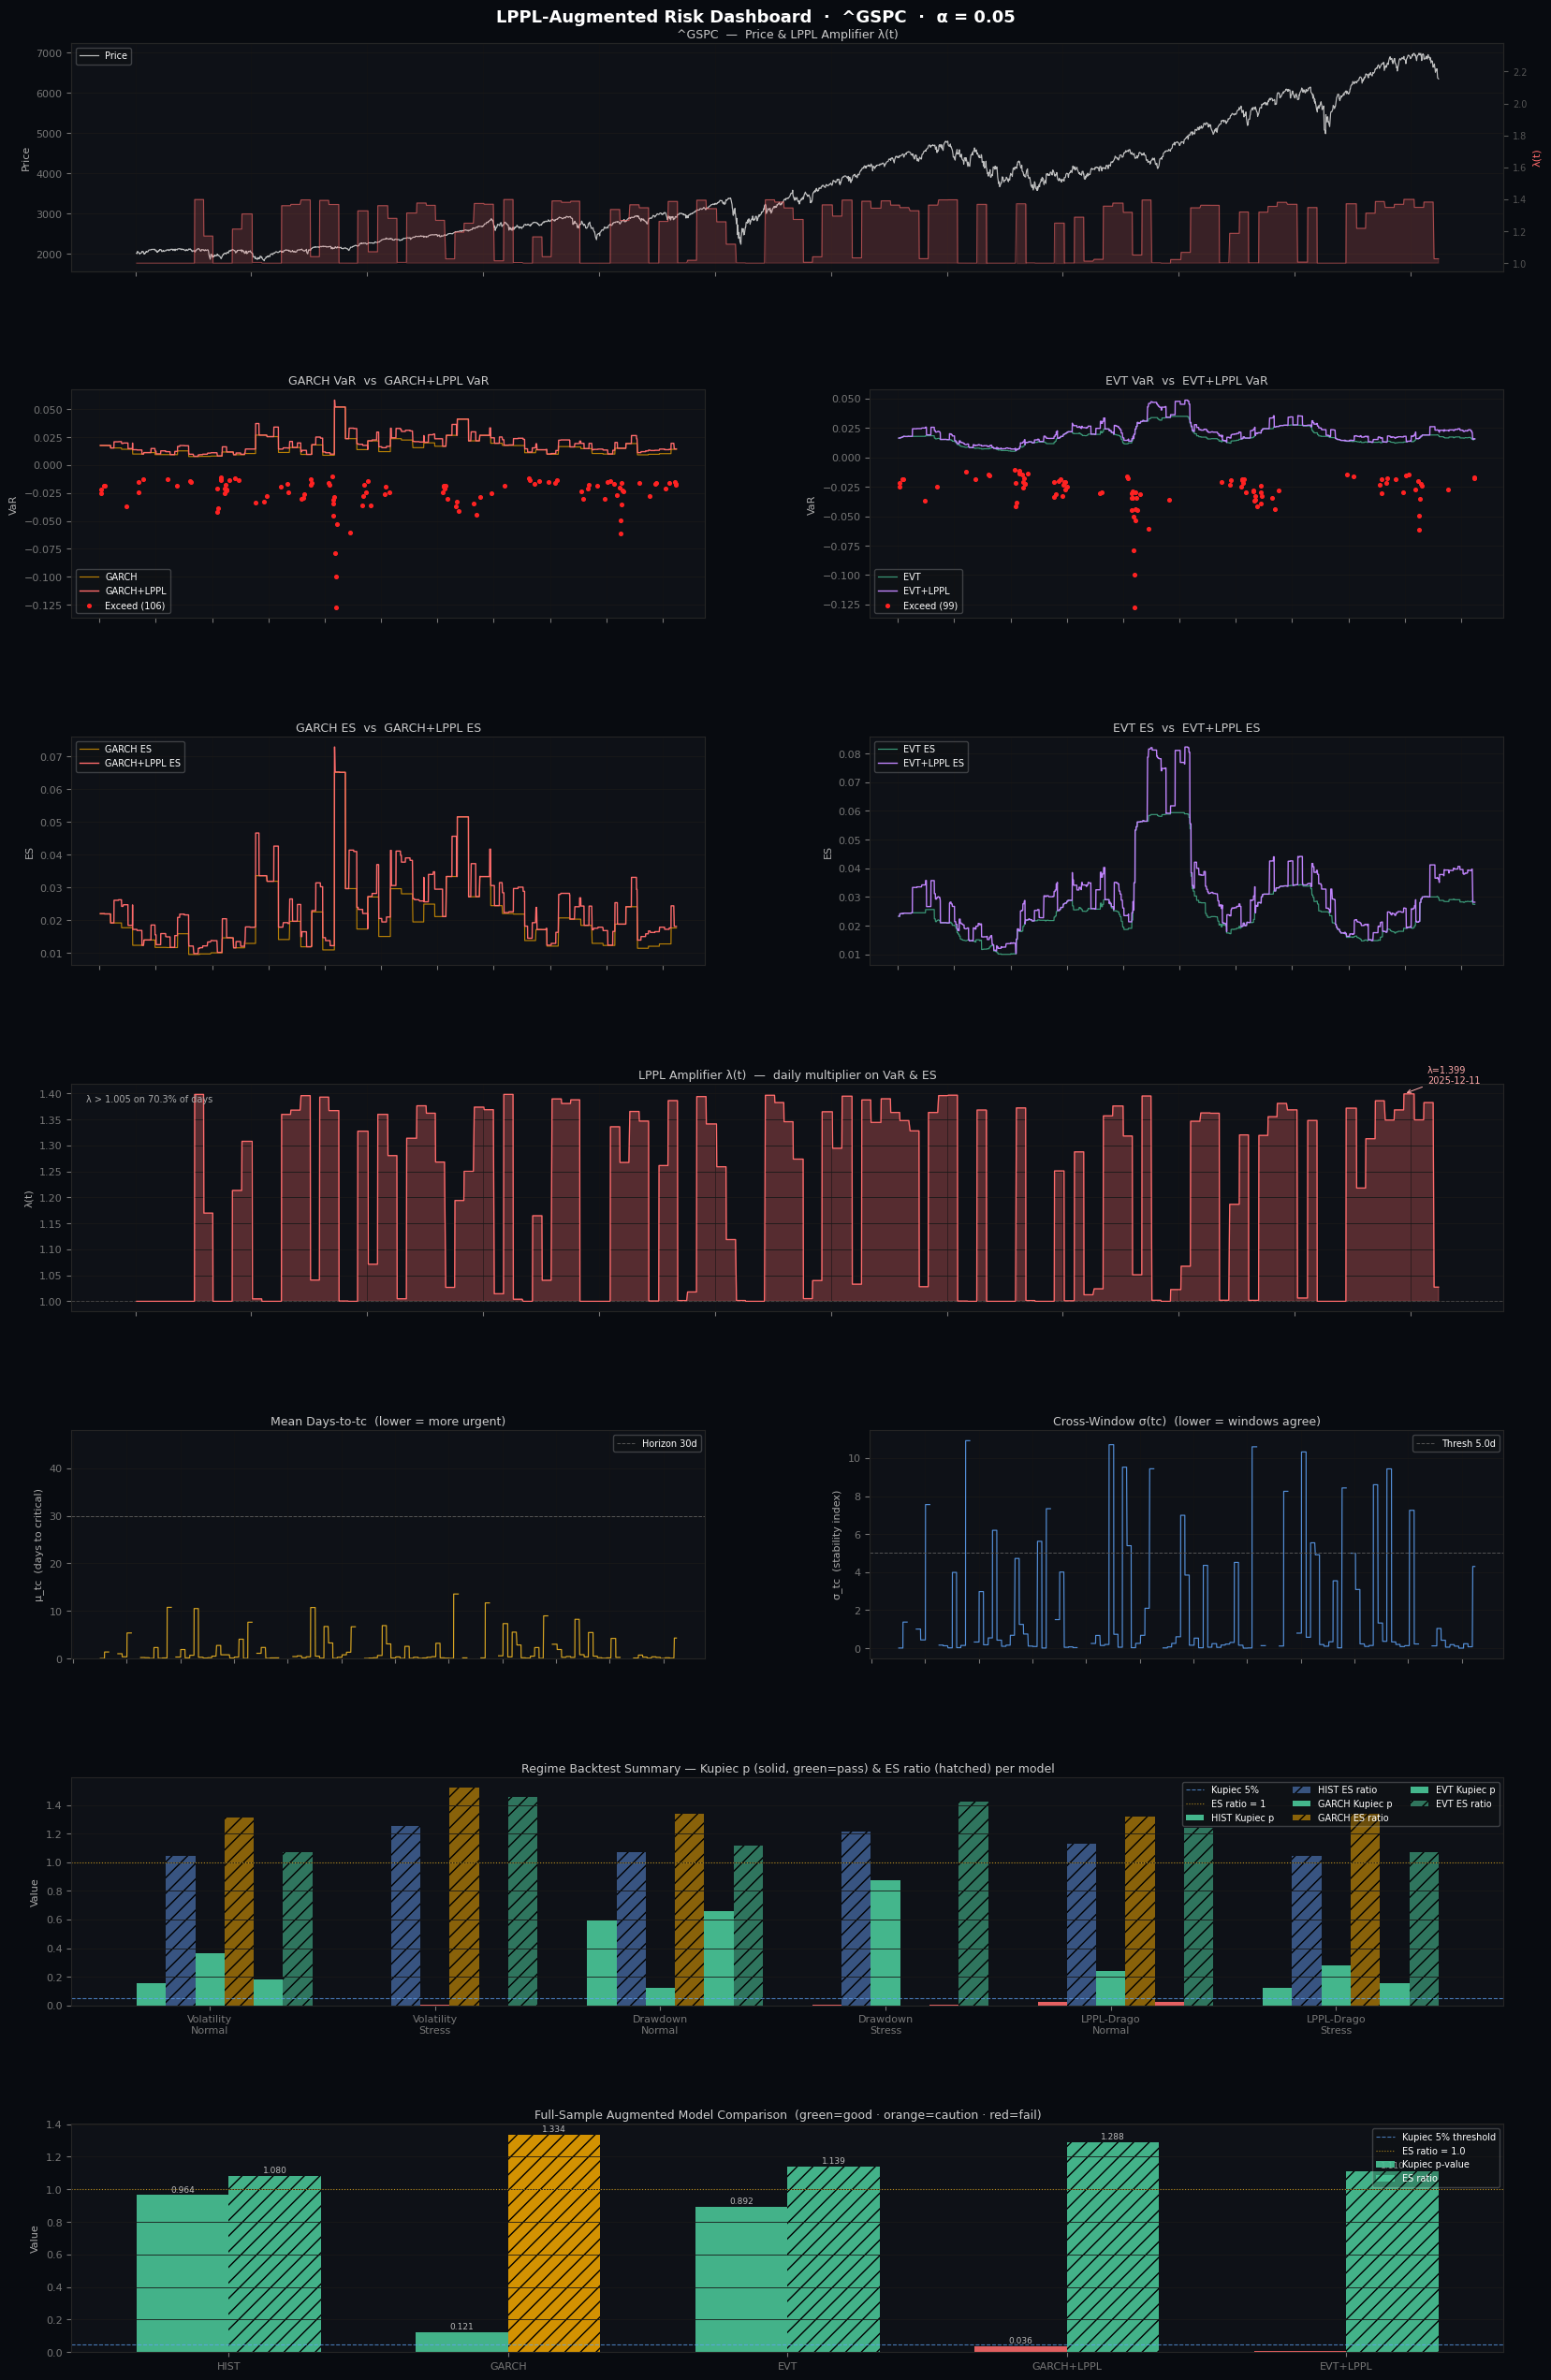

In [7]:
"""
LPPL-Augmented Market Risk Pipeline
=====================================
Three risk models × three regimes, plus LPPL-amplified variants.

Models   : Historical · GARCH(1,1) · EVT (Peaks-over-Threshold)
Regimes  : Volatility · Drawdown · LPPL Dragon-King (binary label)

LPPL Amplification
------------------
A continuous daily scalar λ(t) ≥ 1 is built from the Sornette fit:

    convergence = exp( -σ_tc  / C )   # 1 when windows agree perfectly
    proximity   = exp( -μ_tc  / H )   # 1 when tc is imminent
    λ(t)        = 1 + gain × convergence × proximity

  σ_tc = cross-window std of tc estimates  (stability index)
  μ_tc = mean days-to-tc across windows
  C    = lppl_convergence_scale  (σ reference, default 2.0)
  H    = lppl_horizon_scale      (day reference, default 8.0)
  gain = lppl_gain               (max amplification, default 0.40)

This formulation activates only when σ_tc is genuinely small (< C)
AND tc is close (< H days), avoiding the always-on problem.

Usage
-----
    python risk_pipeline.py                    # ^GSPC defaults
    python risk_pipeline.py --ticker AAPL
    python risk_pipeline.py --gain 0.5
    python risk_pipeline.py --no-lppl          # skip LPPL (faster)
"""

from __future__ import annotations

import argparse
import logging
import os
import warnings
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s  %(levelname)-8s  %(message)s",
    datefmt="%H:%M:%S",
)
log = logging.getLogger(__name__)

# ──────────────────────────────────────────────────────────────
# Config
# ──────────────────────────────────────────────────────────────

@dataclass
class Config:
    ticker : str   = "^GSPC"
    start  : str   = "2015-01-01"
    alpha  : float = 0.05
    window : int   = 252

    vol_window   : int   = 21
    vol_quantile : float = 0.95
    dd_threshold : float = 0.20

    use_lppl              : bool      = True
    lppl_windows          : List[int] = field(default_factory=lambda: [120, 80, 60, 30])
    lppl_refit_step       : int       = 21
    lppl_tc_horizon       : int       = 30
    lppl_stability_thresh : float     = 5.0

    # Amplifier — exponential decay formulation
    lppl_gain              : float = 0.40  # max extra fraction above 1.0
    lppl_convergence_scale : float = 2.0   # σ_tc reference (days): λ peaks when σ < this
    lppl_horizon_scale     : float = 8.0   # μ_tc reference (days): λ peaks when μ < this

    garch_refit_step : int = 50
    evt_step         : int = 5
    evt_min_exc      : int = 10


# ──────────────────────────────────────────────────────────────
# Data
# ──────────────────────────────────────────────────────────────

def fetch_data(cfg: Config) -> pd.DataFrame:
    try:
        import yfinance as yf
    except ImportError as exc:
        raise SystemExit("pip install yfinance") from exc

    log.info("Downloading %s from %s …", cfg.ticker, cfg.start)
    raw = yf.download(cfg.ticker, start=cfg.start, auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"No data for '{cfg.ticker}'.")

    df = raw[["Close"]].copy()
    df.columns = ["price"]
    df["return"] = np.log(df["price"] / df["price"].shift(1))
    return df.dropna()


# ──────────────────────────────────────────────────────────────
# Classic regimes
# ──────────────────────────────────────────────────────────────

def volatility_regime(r: pd.Series, window: int, quantile: float) -> pd.Series:
    ann_vol = r.rolling(window).std() * np.sqrt(252)
    return (ann_vol >= ann_vol.quantile(quantile)).astype(int).rename("vol_regime")


def drawdown_regime(price: pd.Series, threshold: float) -> pd.Series:
    dd = (price - price.cummax()) / price.cummax()
    return (dd <= -threshold).astype(int).rename("dd_regime")


# ──────────────────────────────────────────────────────────────
# LPPL core
# ──────────────────────────────────────────────────────────────

def _solve_lppl_linear(
    tc: float, m: float, w: float,
    t: np.ndarray, p: np.ndarray,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    tau = np.maximum(tc - t, 1e-4)
    lg  = np.log(tau)
    f   = tau ** m
    g   = tau ** m * np.cos(w * lg)
    h   = tau ** m * np.sin(w * lg)
    X   = np.column_stack([np.ones(len(t)), f, g, h])
    sol, *_ = np.linalg.lstsq(X, p, rcond=None)
    return sol, f, g, h


def _lppl_cost(params, t, p, tc_max):
    tc, m, w = params
    if not (t[-1] < tc <= t[-1] + tc_max): return 1e22
    if not (0.05 <= m <= 0.45):            return 1e22
    if not (5.0  <= w <= 15.0):            return 1e22
    try:
        lin, f, g, h = _solve_lppl_linear(tc, m, w, t, p)
    except np.linalg.LinAlgError:
        return 1e22
    A, B, C1, C2 = lin
    if B >= 0:                             return 1e22
    if np.sqrt(C1**2 + C2**2) > abs(B):   return 1e22
    y   = A + B*f + C1*g + C2*h
    mse = float(np.mean((y - p)**2))
    return mse * (1.0 + (tc - t[-1]) / 5.0)


def _fit_lppl(t: np.ndarray, p: np.ndarray, tc_max: int) -> Optional[float]:
    best_c, best_x0 = 1e30, None
    for tc_g in np.linspace(t[-1]+2, t[-1]+tc_max, 5):
        for m_g in [0.1, 0.25, 0.4]:
            for w_g in [6., 10., 14.]:
                c = _lppl_cost([tc_g, m_g, w_g], t, p, tc_max)
                if c < best_c:
                    best_c, best_x0 = c, [tc_g, m_g, w_g]
    if best_x0 is None or best_c > 1e20:
        return None
    res = minimize(_lppl_cost, best_x0, args=(t, p, tc_max),
                   method="Nelder-Mead",
                   options={"xatol": 1e-6, "fatol": 1e-9, "maxiter": 2000})
    return float(res.x[0] - t[-1]) if res.fun < 1e20 else None


# ──────────────────────────────────────────────────────────────
# LPPL Amplifier  — continuous λ(t)
# ──────────────────────────────────────────────────────────────

class LPPLAmplifier:
    """
    Builds three aligned series:
      lam    : daily amplifier λ(t) ≥ 1.0
      mu_tc  : mean days-to-critical across windows
      sig_tc : cross-window σ of tc estimates (stability index)

    Amplifier formula (exponential decay — only fires when *both*
    convergence AND proximity are genuine):

        convergence = exp( -σ_tc / C )
        proximity   = exp( -μ_tc / H )
        λ = 1 + gain × convergence × proximity

    When σ_tc >> C or μ_tc >> H the signal collapses to ~0,
    so λ ≈ 1 (no amplification). This prevents the always-on problem.
    """

    def __init__(self, cfg: Config) -> None:
        self.cfg = cfg

    def build(self, price: pd.Series) -> Tuple[pd.Series, pd.Series, pd.Series]:
        cfg     = self.cfg
        log_p   = np.log(price.values).astype(np.float64)
        n       = len(price)
        min_win = max(cfg.lppl_windows)

        lam_arr = np.ones(n)
        mu_arr  = np.full(n, np.nan)
        sig_arr = np.full(n, np.nan)

        last_lam, last_mu, last_sig = 1.0, np.nan, np.nan

        log.info("Computing LPPL amplifier (refit every %d days) …",
                 cfg.lppl_refit_step)

        for i in range(min_win, n):
            if i % cfg.lppl_refit_step != 0:
                lam_arr[i] = last_lam
                mu_arr[i]  = last_mu
                sig_arr[i] = last_sig
                continue

            deltas: List[float] = []
            for win in cfg.lppl_windows:
                if i < win:
                    continue
                d = _fit_lppl(
                    np.arange(win, dtype=np.float64),
                    log_p[i - win : i],
                    cfg.lppl_tc_horizon,
                )
                if d is not None and 0 < d:
                    deltas.append(d)

            if len(deltas) < 2:
                last_lam, last_mu, last_sig = 1.0, np.nan, np.nan
            else:
                mu  = float(np.mean(deltas))
                sig = float(np.std(deltas))

                # Exponential decay: only activates when σ < C AND μ < H
                convergence = float(np.exp(-sig / cfg.lppl_convergence_scale))
                proximity   = float(np.exp(-mu  / cfg.lppl_horizon_scale))
                last_lam    = 1.0 + cfg.lppl_gain * convergence * proximity
                last_mu, last_sig = mu, sig

            lam_arr[i] = last_lam
            mu_arr[i]  = last_mu
            sig_arr[i] = last_sig

        idx = price.index
        return (
            pd.Series(lam_arr, index=idx, name="lppl_lambda"),
            pd.Series(mu_arr,  index=idx, name="lppl_mu_tc"),
            pd.Series(sig_arr, index=idx, name="lppl_sig_tc"),
        )


# ──────────────────────────────────────────────────────────────
# LPPL binary regime (for the regime comparison table)
# ──────────────────────────────────────────────────────────────

def lppl_binary_regime(
    lam: pd.Series, mu_tc: pd.Series, sig_tc: pd.Series, cfg: Config
) -> pd.Series:
    """
    1 = stress: tc within horizon AND windows converged below thresh.
    Derived from the amplifier series so no extra fitting needed.
    """
    stress = (
        mu_tc.fillna(999)  < cfg.lppl_tc_horizon
    ) & (
        sig_tc.fillna(999) < cfg.lppl_stability_thresh
    )
    return stress.astype(int).rename("lppl_regime")


# ──────────────────────────────────────────────────────────────
# Risk Models
# ──────────────────────────────────────────────────────────────

class RiskModels:
    def __init__(self, cfg: Config) -> None:
        self.cfg = cfg

    def historical(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        w, a = self.cfg.window, self.cfg.alpha
        var = -r.rolling(w).quantile(a)
        es  =  r.rolling(w).apply(
            lambda x: -x[x <= np.quantile(x, a)].mean(), raw=True)
        return var, es

    def garch(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        cfg = self.cfg
        q_z   = stats.norm.ppf(cfg.alpha)
        pdf_z = stats.norm.pdf(q_z)
        var_list, es_list, last_res = [], [], None
        log.info("Fitting GARCH(1,1) …")
        for i in range(cfg.window, len(r)):
            if last_res is None or i % cfg.garch_refit_step == 0:
                try:
                    last_res = arch_model(
                        r.iloc[:i]*100, vol="Garch", p=1, q=1, dist="normal"
                    ).fit(disp="off")
                except Exception:
                    pass
            if last_res is None:
                var_list.append(np.nan); es_list.append(np.nan); continue
            sig = np.sqrt(last_res.forecast(horizon=1).variance.values[-1, 0]) / 100
            var_list.append(-sig * q_z)
            es_list.append( sig * pdf_z / cfg.alpha)
        idx = r.index[cfg.window:]
        return pd.Series(var_list, idx), pd.Series(es_list, idx)

    def evt(self, r: pd.Series) -> Tuple[pd.Series, pd.Series]:
        cfg = self.cfg
        var_list, es_list = [], []
        lv = le = np.nan
        log.info("Fitting EVT (GPD) …")
        for i in range(cfg.window, len(r)):
            if i % cfg.evt_step != 0:
                var_list.append(lv); es_list.append(le); continue
            losses = -r.iloc[i - cfg.window : i].values
            u      = np.percentile(losses, 90)
            exc    = losses[losses > u] - u
            if len(exc) < cfg.evt_min_exc:
                v = float(np.percentile(losses, (1 - cfg.alpha) * 100))
                e = float(losses[losses > v].mean()) if (losses > v).any() else v
            else:
                xi, _, beta = stats.genpareto.fit(exc, floc=0)
                nu, n = len(exc), len(losses)
                v = (u + (beta/xi)*((n/nu*cfg.alpha)**(-xi)-1)
                     if xi != 0 else u - beta*np.log(n/nu*cfg.alpha))
                e = (v + beta - xi*u)/(1-xi) if xi < 1 else v
            lv, le = float(v), float(e)
            var_list.append(lv); es_list.append(le)
        idx = r.index[cfg.window:]
        return pd.Series(var_list, idx), pd.Series(es_list, idx)


# ──────────────────────────────────────────────────────────────
# Backtests
# ──────────────────────────────────────────────────────────────

def kupiec_pof(returns: pd.Series, var: pd.Series, alpha: float) -> float:
    hits = (returns < -var).astype(int)
    x, N = int(hits.sum()), len(hits)
    if x == 0 or x == N:
        return np.nan
    p  = x / N
    lr = -2*(x*np.log(alpha/p) + (N-x)*np.log((1-alpha)/(1-p)))
    return float(1 - stats.chi2.cdf(lr, 1))


def es_ratio(returns: pd.Series, var: pd.Series, es: pd.Series) -> float:
    mask = returns < -var
    if mask.sum() < 10:
        return np.nan
    tail, fc = -returns[mask], es[mask]
    ok = fc > 0
    return float((tail[ok]/fc[ok]).mean()) if ok.sum() >= 5 else np.nan


def regime_backtest(
    r: pd.Series,
    risk: pd.DataFrame,
    regimes: Dict[str, pd.Series],
    cfg: Config,
) -> pd.DataFrame:
    """Per-regime × per-state × base-model backtest (no augmented cols)."""
    records = []
    for regime_name, regime_series in regimes.items():
        aligned = regime_series.reindex(risk.index)
        for regime_val, state_label in [(0, "Normal"), (1, "Stress")]:
            mask  = aligned == regime_val
            sub_r = r.reindex(risk.index)[mask]
            for model in ["hist", "garch", "evt"]:
                var = risk[f"var_{model}"][mask]
                es_ = risk[f"es_{model}"][mask]
                kp  = kupiec_pof(sub_r, var, cfg.alpha)
                zr  = es_ratio(sub_r, var, es_)
                records.append({
                    "regime":   regime_name,
                    "state":    state_label,
                    "model":    model.upper(),
                    "n_obs":    int(mask.sum()),
                    "n_exceed": int((sub_r < -var).sum()),
                    "kupiec_p": round(kp, 4) if pd.notna(kp) else np.nan,
                    "es_ratio": round(zr, 3) if pd.notna(zr) else np.nan,
                })
    return pd.DataFrame(records)


def augmented_backtest(
    r: pd.Series, risk: pd.DataFrame, cfg: Config
) -> pd.DataFrame:
    """Whole-sample backtest comparing base vs LPPL-augmented models."""
    rows = []
    pairs = [
        ("HIST",      "var_hist",      "es_hist"),
        ("GARCH",     "var_garch",     "es_garch"),
        ("EVT",       "var_evt",       "es_evt"),
        ("GARCH+LPPL","var_garch_aug", "es_garch_aug"),
        ("EVT+LPPL",  "var_evt_aug",   "es_evt_aug"),
    ]
    r_al = r.reindex(risk.index)
    for label, vc, ec in pairs:
        if vc not in risk.columns:
            continue
        kp = kupiec_pof(r_al, risk[vc], cfg.alpha)
        zr = es_ratio(r_al, risk[vc], risk[ec])
        rows.append({
            "model":    label,
            "n_obs":    len(risk),
            "n_exceed": int((r_al < -risk[vc]).sum()),
            "kupiec_p": round(kp, 4) if pd.notna(kp) else np.nan,
            "es_ratio": round(zr, 3) if pd.notna(zr) else np.nan,
        })
    return pd.DataFrame(rows)


# ──────────────────────────────────────────────────────────────
# Print tables
# ──────────────────────────────────────────────────────────────

def print_regime_table(df: pd.DataFrame, cfg: Config) -> None:
    sep = "─" * 76
    hdr = (f"{'Regime':<16}{'State':<10}{'Model':<8}"
           f"{'N':>6}{'Exceeds':>9}{'Kupiec p':>11}{'ES ratio':>10}  Pass")
    print(f"\n{'Regime Backtest (base models)':^76}")
    print(f"Ticker: {cfg.ticker}  |  α={cfg.alpha}  |  window={cfg.window}d")
    print(sep); print(hdr); print(sep)
    prev = None
    for _, row in df.iterrows():
        if row["regime"] != prev:
            if prev is not None:
                print()
            prev = row["regime"]
        kp = f"{row['kupiec_p']:.4f}" if pd.notna(row["kupiec_p"]) else "   n/a"
        zr = f"{row['es_ratio']:.3f}" if pd.notna(row["es_ratio"]) else "   n/a"
        ok = "✓" if (pd.notna(row["kupiec_p"]) and row["kupiec_p"] > 0.05) else "✗"
        print(f"{row['regime']:<16}{row['state']:<10}{row['model']:<8}"
              f"{row['n_obs']:>6}{row['n_exceed']:>9}{kp:>11}{zr:>10}  {ok}")
    print(sep)
    print("✓ Kupiec p > 0.05  →  VaR not rejected at 5% level")
    print("ES ratio ≈ 1.0     →  ES well-calibrated  (> 1 = underestimated)\n")


def print_augmented_table(df: pd.DataFrame, cfg: Config, lam: pd.Series) -> None:
    sep = "─" * 66
    hdr = (f"{'Model':<14}{'N':>6}{'Exceeds':>9}"
           f"{'Kupiec p':>11}{'ES ratio':>10}  Pass")
    print(f"\n{'LPPL-Augmented Model Comparison (full sample)':^66}")
    print(f"LPPL gain={cfg.lppl_gain}  |  "
          f"λ_mean={lam.mean():.4f}  |  λ_max={lam.max():.4f}  |  "
          f"λ>1.05 on {(lam > 1.05).mean():.1%} of days")
    print(sep); print(hdr); print(sep)
    for i, (_, row) in enumerate(df.iterrows()):
        if i == 3:
            print()   # blank line between base and augmented
        kp = f"{row['kupiec_p']:.4f}" if pd.notna(row["kupiec_p"]) else "   n/a"
        zr = f"{row['es_ratio']:.3f}" if pd.notna(row["es_ratio"]) else "   n/a"
        ok = "✓" if (pd.notna(row["kupiec_p"]) and row["kupiec_p"] > 0.05) else "✗"
        print(f"{row['model']:<14}{row['n_obs']:>6}{row['n_exceed']:>9}"
              f"{kp:>11}{zr:>10}  {ok}")
    print(sep)
    print("Base models above the blank line; LPPL-augmented below.\n")


# ──────────────────────────────────────────────────────────────
# Plotting
# ──────────────────────────────────────────────────────────────

COLORS = {
    "price"     : "#d4d4d4",
    "hist"      : "#5b8dd9",
    "garch"     : "#f0a500",
    "evt"       : "#4bc99a",
    "garch_aug" : "#ff6b6b",
    "evt_aug"   : "#c084fc",
    "lambda"    : "#ff6b6b",
    "exceed"    : "#ff2222",
    "mu"        : "#fbbf24",
    "sig"       : "#60a5fa",
}

BG   = "#080b10"
PANEL = "#0e1117"


def _style_ax(ax, ylabel="", x_labels=False):
    ax.set_facecolor(PANEL)
    ax.tick_params(colors="#777", labelsize=8)
    ax.yaxis.label.set_color("#aaa")
    for spine in ax.spines.values():
        spine.set_edgecolor("#252525")
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=8)
    ax.grid(axis="y", color="#191919", linewidth=0.6)
    ax.grid(axis="x", color="#141414", linewidth=0.4)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    if not x_labels:
        ax.tick_params(labelbottom=False)


def _legend(ax, **kw):
    ax.legend(fontsize=7, framealpha=0.25, labelcolor="white",
              facecolor="#111", **kw)


def plot_results(
    df      : pd.DataFrame,
    risk    : pd.DataFrame,
    lam     : pd.Series,
    mu_tc   : pd.Series,
    sig_tc  : pd.Series,
    reg_bt  : pd.DataFrame,
    aug_bt  : pd.DataFrame,
    cfg     : Config,
) -> str:
    r     = df["return"]
    price = df["price"]
    idx   = risk.index
    r_idx = r.reindex(idx)

    fig = plt.figure(figsize=(17, 26), facecolor=BG)
    fig.suptitle(
        f"LPPL-Augmented Risk Dashboard  ·  {cfg.ticker}  ·  α = {cfg.alpha}",
        color="white", fontsize=13, fontweight="bold", y=0.998,
    )

    gs = fig.add_gridspec(
        7, 2, hspace=0.52, wspace=0.26,
        left=0.07, right=0.97, top=0.984, bottom=0.035,
    )

    # ── Row 0 (full): Price + λ shading ─────────────────────────────
    ax0 = fig.add_subplot(gs[0, :])
    _style_ax(ax0, ylabel="Price")
    ax0.plot(price.index, price, color=COLORS["price"], lw=0.85, alpha=0.9,
             label="Price")
    ax0r = ax0.twinx()
    ax0r.set_facecolor(PANEL)
    ax0r.fill_between(lam.index, 1.0, lam.values, where=lam > 1.005,
                      color=COLORS["lambda"], alpha=0.18, label="λ > 1")
    ax0r.plot(lam.index, lam.values, color=COLORS["lambda"],
              lw=0.7, alpha=0.55)
    ax0r.set_ylim(0.95, lam.max() * 1.7)
    ax0r.tick_params(colors="#555", labelsize=7)
    ax0r.set_ylabel("λ(t)", color=COLORS["lambda"], fontsize=8)
    for sp in ax0r.spines.values(): sp.set_edgecolor("#252525")
    ax0.set_title(f"{cfg.ticker}  —  Price & LPPL Amplifier λ(t)",
                  color="#ccc", fontsize=9, pad=4)
    _legend(ax0, loc="upper left")

    # ── Row 1L: GARCH VaR base vs augmented ─────────────────────────
    ax1 = fig.add_subplot(gs[1, 0])
    _style_ax(ax1, ylabel="VaR")
    ax1.plot(idx, risk["var_garch"],    color=COLORS["garch"],    lw=0.85,
             alpha=0.75, label="GARCH")
    ax1.plot(idx, risk["var_garch_aug"],color=COLORS["garch_aug"],lw=1.0,
             label="GARCH+LPPL")
    exc = r_idx < -risk["var_garch_aug"]
    ax1.scatter(idx[exc], r_idx[exc], color=COLORS["exceed"], s=7, zorder=5,
                label=f"Exceed ({exc.sum()})")
    ax1.set_title("GARCH VaR  vs  GARCH+LPPL VaR", color="#ccc", fontsize=9, pad=4)
    _legend(ax1, loc="lower left")

    # ── Row 1R: EVT VaR ─────────────────────────────────────────────
    ax2 = fig.add_subplot(gs[1, 1])
    _style_ax(ax2, ylabel="VaR")
    ax2.plot(idx, risk["var_evt"],    color=COLORS["evt"],    lw=0.85,
             alpha=0.75, label="EVT")
    ax2.plot(idx, risk["var_evt_aug"],color=COLORS["evt_aug"],lw=1.0,
             label="EVT+LPPL")
    exc2 = r_idx < -risk["var_evt_aug"]
    ax2.scatter(idx[exc2], r_idx[exc2], color=COLORS["exceed"], s=7, zorder=5,
                label=f"Exceed ({exc2.sum()})")
    ax2.set_title("EVT VaR  vs  EVT+LPPL VaR", color="#ccc", fontsize=9, pad=4)
    _legend(ax2, loc="lower left")

    # ── Row 2L: GARCH ES ─────────────────────────────────────────────
    ax3 = fig.add_subplot(gs[2, 0])
    _style_ax(ax3, ylabel="ES")
    ax3.plot(idx, risk["es_garch"],    color=COLORS["garch"],    lw=0.85,
             alpha=0.75, label="GARCH ES")
    ax3.plot(idx, risk["es_garch_aug"],color=COLORS["garch_aug"],lw=1.0,
             label="GARCH+LPPL ES")
    ax3.set_title("GARCH ES  vs  GARCH+LPPL ES", color="#ccc", fontsize=9, pad=4)
    _legend(ax3, loc="upper left")

    # ── Row 2R: EVT ES ───────────────────────────────────────────────
    ax4 = fig.add_subplot(gs[2, 1])
    _style_ax(ax4, ylabel="ES")
    ax4.plot(idx, risk["es_evt"],    color=COLORS["evt"],    lw=0.85,
             alpha=0.75, label="EVT ES")
    ax4.plot(idx, risk["es_evt_aug"],color=COLORS["evt_aug"],lw=1.0,
             label="EVT+LPPL ES")
    ax4.set_title("EVT ES  vs  EVT+LPPL ES", color="#ccc", fontsize=9, pad=4)
    _legend(ax4, loc="upper left")

    # ── Row 3 (full): λ(t) ───────────────────────────────────────────
    ax5 = fig.add_subplot(gs[3, :])
    _style_ax(ax5, ylabel="λ(t)")
    ax5.axhline(1.0, color="#444", lw=0.7, ls="--")
    ax5.fill_between(lam.index, 1.0, lam.values, where=lam > 1.0,
                     color=COLORS["lambda"], alpha=0.3)
    ax5.plot(lam.index, lam.values, color=COLORS["lambda"], lw=0.9)
    peak_d = lam.idxmax()
    ax5.annotate(f"λ={lam.max():.3f}\n{peak_d.date()}",
                 xy=(peak_d, lam.max()),
                 xytext=(18, 8), textcoords="offset points",
                 color="#ffaaaa", fontsize=7,
                 arrowprops=dict(arrowstyle="->", color="#ffaaaa", lw=0.7))
    ax5.set_title("LPPL Amplifier λ(t)  —  daily multiplier on VaR & ES",
                  color="#ccc", fontsize=9, pad=4)
    frac = (lam > 1.005).mean()
    ax5.text(0.01, 0.92, f"λ > 1.005 on {frac:.1%} of days",
             transform=ax5.transAxes, color="#aaa", fontsize=7)

    # ── Row 4L: μ_tc ─────────────────────────────────────────────────
    ax6 = fig.add_subplot(gs[4, 0])
    _style_ax(ax6, ylabel="μ_tc  (days to critical)")
    ax6.plot(mu_tc.index, mu_tc.values, color=COLORS["mu"], lw=0.85, alpha=0.85)
    ax6.axhline(cfg.lppl_tc_horizon, color="#555", lw=0.7, ls="--",
                label=f"Horizon {cfg.lppl_tc_horizon}d")
    ax6.set_ylim(0, cfg.lppl_tc_horizon * 1.6)
    ax6.set_title("Mean Days-to-tc  (lower = more urgent)",
                  color="#ccc", fontsize=9, pad=4)
    _legend(ax6)

    # ── Row 4R: σ_tc ─────────────────────────────────────────────────
    ax7 = fig.add_subplot(gs[4, 1])
    _style_ax(ax7, ylabel="σ_tc  (stability index)")
    ax7.plot(sig_tc.index, sig_tc.values, color=COLORS["sig"], lw=0.85, alpha=0.85)
    ax7.axhline(cfg.lppl_stability_thresh, color="#555", lw=0.7, ls="--",
                label=f"Thresh {cfg.lppl_stability_thresh}d")
    ax7.set_title("Cross-Window σ(tc)  (lower = windows agree)",
                  color="#ccc", fontsize=9, pad=4)
    _legend(ax7)

    # ── Row 5 (full): Regime backtest heatmap ────────────────────────
    ax8 = fig.add_subplot(gs[5, :])
    ax8.set_facecolor(PANEL)
    for sp in ax8.spines.values(): sp.set_edgecolor("#252525")

    regimes_order = reg_bt["regime"].unique().tolist()
    cell_data, row_labels, col_labels = [], [], []
    col_labels = []
    for reg in regimes_order:
        for state in ["Normal", "Stress"]:
            sub = reg_bt[(reg_bt["regime"] == reg) & (reg_bt["state"] == state)]
            col_labels.append(f"{reg[:9]}\n{state}")
            for _, row in sub.iterrows():
                pass  # just need the structure

    # Build matrix: rows = models, cols = regime×state
    models_order = ["HIST", "GARCH", "EVT"]
    matrix_kp = np.full((3, len(regimes_order)*2), np.nan)
    matrix_er = np.full((3, len(regimes_order)*2), np.nan)
    col_idx = 0
    col_labels = []
    for reg in regimes_order:
        for state in ["Normal", "Stress"]:
            col_labels.append(f"{reg[:10]}\n{state}")
            sub = reg_bt[(reg_bt["regime"] == reg) & (reg_bt["state"] == state)]
            for mi, mdl in enumerate(models_order):
                row_m = sub[sub["model"] == mdl]
                if not row_m.empty:
                    matrix_kp[mi, col_idx] = float(row_m["kupiec_p"].iloc[0]) if pd.notna(row_m["kupiec_p"].iloc[0]) else np.nan
                    matrix_er[mi, col_idx] = float(row_m["es_ratio"].iloc[0])  if pd.notna(row_m["es_ratio"].iloc[0])  else np.nan
            col_idx += 1

    x = np.arange(len(col_labels))
    bar_w = 0.13
    offsets = [-2, -1, 0, 1, 2]  # 5 bars: HIST kp, HIST er, GARCH kp ...
    model_colors = [COLORS["hist"], COLORS["garch"], COLORS["evt"]]

    for mi, (mdl, col) in enumerate(zip(models_order, model_colors)):
        kp_vals = matrix_kp[mi]
        er_vals = matrix_er[mi]
        kp_colors = ["#4bc99a" if (not np.isnan(v) and v > 0.05) else "#ff6b6b"
                     for v in kp_vals]
        ax8.bar(x + (mi*2 - 2)*bar_w, np.nan_to_num(kp_vals), bar_w,
                color=kp_colors, alpha=0.9, label=f"{mdl} Kupiec p")
        ax8.bar(x + (mi*2 - 1)*bar_w, np.nan_to_num(er_vals), bar_w,
                color=col, alpha=0.55, label=f"{mdl} ES ratio", hatch="//")

    ax8.axhline(0.05, color="#60a5fa", lw=0.8, ls="--", alpha=0.7,
                label="Kupiec 5%")
    ax8.axhline(1.00, color="#fbbf24", lw=0.8, ls=":", alpha=0.7,
                label="ES ratio = 1")
    ax8.set_xticks(x)
    ax8.set_xticklabels(col_labels, color="#ccc", fontsize=7.5)
    ax8.tick_params(colors="#777", labelsize=8)
    ax8.set_ylabel("Value", color="#aaa", fontsize=8)
    ax8.set_title(
        "Regime Backtest Summary — Kupiec p (solid, green=pass) & ES ratio (hatched) per model",
        color="#ccc", fontsize=9, pad=4,
    )
    ax8.grid(axis="y", color="#191919", linewidth=0.6)
    _legend(ax8, loc="upper right", ncol=3)

    # ── Row 6 (full): Augmented model comparison bar chart ───────────
    ax9 = fig.add_subplot(gs[6, :])
    ax9.set_facecolor(PANEL)
    for sp in ax9.spines.values(): sp.set_edgecolor("#252525")

    mdls    = aug_bt["model"].tolist()
    kp_v    = aug_bt["kupiec_p"].fillna(0).tolist()
    er_v    = aug_bt["es_ratio"].fillna(0).tolist()
    xb      = np.arange(len(mdls))
    bw      = 0.33
    bkp_col = ["#4bc99a" if v > 0.05 else "#ff6b6b" for v in kp_v]
    ber_col = ["#4bc99a" if 0.85 < v < 1.3 else
               "#f0a500" if v < 1.6 else "#ff6b6b" for v in er_v]

    b1 = ax9.bar(xb - bw/2, kp_v, bw, color=bkp_col, alpha=0.88,
                 label="Kupiec p-value")
    b2 = ax9.bar(xb + bw/2, er_v, bw, color=ber_col, alpha=0.88,
                 label="ES ratio", hatch="//")
    ax9.axhline(0.05, color="#60a5fa", lw=0.8, ls="--", alpha=0.7,
                label="Kupiec 5% threshold")
    ax9.axhline(1.00, color="#fbbf24", lw=0.8, ls=":", alpha=0.7,
                label="ES ratio = 1.0")
    ax9.set_xticks(xb)
    ax9.set_xticklabels(mdls, color="#ccc", fontsize=9)
    ax9.tick_params(colors="#777", labelsize=8, labelbottom=True)
    ax9.set_ylabel("Value", color="#aaa", fontsize=8)
    ax9.set_title(
        "Full-Sample Augmented Model Comparison  (green=good · orange=caution · red=fail)",
        color="#ccc", fontsize=9, pad=4,
    )
    _legend(ax9, loc="upper right")
    ax9.grid(axis="y", color="#191919", linewidth=0.6)
    for bar in list(b1) + list(b2):
        v = bar.get_height()
        if v > 0.01:
            ax9.text(bar.get_x() + bar.get_width()/2, v + 0.008,
                     f"{v:.3f}", ha="center", va="bottom",
                     color="#bbb", fontsize=6.5)

    # Save next to the script so it always works regardless of CWD
    script_dir = os.path.dirname(os.path.abspath(__file__))
    out_path   = os.path.join(script_dir, f"risk_dashboard_{cfg.ticker.replace('^','')}.png")
    plt.savefig(out_path, dpi=150, bbox_inches="tight", facecolor=BG)
    log.info("Plot saved → %s", out_path)
    plt.close()
    return out_path


# ──────────────────────────────────────────────────────────────
# Run
# ──────────────────────────────────────────────────────────────

def run(cfg: Config | None = None):
    if cfg is None:
        cfg = Config()

    df = fetch_data(cfg)
    r  = df["return"]

    # Base risk models
    rm = RiskModels(cfg)
    log.info("Computing base risk models …")
    v_hist,  e_hist  = rm.historical(r)
    v_garch, e_garch = rm.garch(r)
    v_evt,   e_evt   = rm.evt(r)

    risk = pd.DataFrame({
        "var_hist":  v_hist,  "es_hist":   e_hist,
        "var_garch": v_garch, "es_garch":  e_garch,
        "var_evt":   v_evt,   "es_evt":    e_evt,
    }).dropna()

    # LPPL amplifier
    lam    = pd.Series(np.ones(len(df)), index=df.index)
    mu_tc  = pd.Series(np.nan, index=df.index)
    sig_tc = pd.Series(np.nan, index=df.index)

    if cfg.use_lppl:
        log.info("Building LPPL amplifier …")
        lam, mu_tc, sig_tc = LPPLAmplifier(cfg).build(df["price"])

    lam_r = lam.reindex(risk.index).fillna(1.0)
    risk["var_garch_aug"] = risk["var_garch"] * lam_r
    risk["es_garch_aug"]  = risk["es_garch"]  * lam_r
    risk["var_evt_aug"]   = risk["var_evt"]   * lam_r
    risk["es_evt_aug"]    = risk["es_evt"]    * lam_r

    # Classic regimes + LPPL binary
    regimes: Dict[str, pd.Series] = {
        "Volatility": volatility_regime(r, cfg.vol_window, cfg.vol_quantile),
        "Drawdown":   drawdown_regime(df["price"], cfg.dd_threshold),
    }
    if cfg.use_lppl:
        regimes["LPPL-DragonKing"] = lppl_binary_regime(lam, mu_tc, sig_tc, cfg)
        n_stress = int(regimes["LPPL-DragonKing"].sum())
        log.info("LPPL stress days: %d / %d (%.1f%%)",
                 n_stress, len(lam), n_stress / len(lam) * 100)

    reg_bt = regime_backtest(r, risk, regimes, cfg)
    aug_bt = augmented_backtest(r, risk, cfg)

    print_regime_table(reg_bt, cfg)
    print_augmented_table(aug_bt, cfg, lam)

    log.info("Generating plots …")
    plot_results(df, risk, lam, mu_tc, sig_tc, reg_bt, aug_bt, cfg)

    return risk, reg_bt, aug_bt


# ──────────────────────────────────────────────────────────────
# CLI
# ──────────────────────────────────────────────────────────────

def _is_jupyter() -> bool:
    try:
        return get_ipython().__class__.__name__ in (   # type: ignore
            "ZMQInteractiveShell", "TerminalInteractiveShell")
    except NameError:
        return False


def _parse_args() -> Config:
    p = argparse.ArgumentParser(
        description=__doc__,
        formatter_class=argparse.RawDescriptionHelpFormatter,
    )
    p.add_argument("--ticker",  default="^GSPC")
    p.add_argument("--start",   default="2015-01-01")
    p.add_argument("--alpha",   type=float, default=0.05)
    p.add_argument("--window",  type=int,   default=252)
    p.add_argument("--gain",    type=float, default=0.40,
                   help="Max LPPL amplification (default 0.40 = +40%%)")
    p.add_argument("--no-lppl", action="store_true",
                   help="Skip LPPL entirely (faster)")
    args, _ = p.parse_known_args()
    return Config(
        ticker=args.ticker, start=args.start,
        alpha=args.alpha,   window=args.window,
        lppl_gain=args.gain, use_lppl=not args.no_lppl,
    )


if __name__ == "__main__" or _is_jupyter():
    run(_parse_args())